# Federated Learning on ISIC 2019 — ResNet50 · DenseNet201 · EfficientNetV2-S
PyTorch + Flower 1.39 (simulation, Message API)
Dataset: Kaggle `salviohexia/isic-2019-skin-lesion-images-for-classification` (25,331 images, 8 classes)

Runs in a VS Code Jupyter notebook with the Anaconda kernel `fl-isic` (see environment.yml).
Images are read directly from LOCAL_DATA_DIR on your PC.

Pipeline: dataset discovery -> 256px cache -> stratified split (train 70 / server-val 10 / test 20)
-> Dirichlet non-IID client partition -> FedAvg -> best round chosen on server-val -> final held-out test report.
First run a smoke test with SUBSET_FRACTION = 0.1 and NUM_ROUNDS = 2.

## 1. Imports

In [1]:
import os, sys, math, json, time, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             roc_curve, auc)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

import flwr
from flwr.app import ArrayRecord, ConfigRecord, Context, Message, MetricRecord, RecordDict
from flwr.clientapp import ClientApp
from flwr.serverapp import Grid, ServerApp
from flwr.serverapp.strategy import FedAvg
from flwr.simulation import run_simulation

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore", category=UserWarning)

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"torchvision {__import__('torchvision').__version__} | flwr {flwr.__version__}")
print("CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

Python 3.11.16 | torch 2.9.1+cu126 | torchvision 0.24.1+cu126 | flwr 1.39.0
CUDA available: True | NVIDIA GeForce RTX 4090


## 2. Configuration — edit only this cell

In [2]:
# ---------- Dataset location ----------
# Folder where you unzipped the Kaggle dataset (any sub-folder layout is fine)
LOCAL_DATA_DIR = r"F:\Rakib\dataset"
# F:\Rakib\dataset

# ---------- Output ----------
OUTPUT_DIR = Path("./fl_isic_outputs")   # checkpoints, histories, figures (next to the notebook)
CACHE_DIR  = Path("./isic_cache_256")    # resized copy of the images (~1 GB, created once)

# ---------- Models ----------
MODELS = ["resnet50", "densenet201", "efficientnet_v2_s"]
PRETRAINED = True               # ImageNet weights (strongly recommended)

# ---------- Data ----------
SUBSET_FRACTION = 1.0           # quick test: 0.1 (stratified subset of the whole dataset)
IMG_SIZE   = 224
CACHE_SIZE = 256                # images are resized once (shorter side) -> much faster training
VAL_FRAC, TEST_FRAC = 0.10, 0.20
LOCAL_VAL_FRAC = 0.10           # each client keeps 10% of its data for local (federated) evaluation

# ---------- Federated setup ----------
NUM_CLIENTS     = 5
PARTITION       = "dirichlet"   # "dirichlet" (non-IID) or "iid"
DIRICHLET_ALPHA = 0.5           # smaller = more heterogeneous
NUM_ROUNDS      = 10
LOCAL_EPOCHS    = 1
FRACTION_TRAIN  = 1.0           # fraction of clients sampled per round
FRACTION_EVAL   = 1.0           # set 0.0 to skip client-side evaluation (faster)

# ---------- Optimisation ----------
BATCH_SIZE   = 32
LR, LR_MIN   = 1e-4, 1e-6       # AdamW, cosine decay over rounds
WEIGHT_DECAY = 1e-4
USE_CLASS_WEIGHTS = True        # ISIC 2019 is highly imbalanced (NV >> DF, VASC)
USE_AMP = True                  # mixed precision on GPU

# ---------- Hardware (Ray resources per virtual client) ----------
NUM_GPUS = torch.cuda.device_count()
CLIENT_NUM_GPUS = 1.0 if NUM_GPUS else 0.0   # 1.0 = clients train one at a time on the GPU (safest)
CLIENT_NUM_CPUS = max(1, min(4, os.cpu_count() or 1))
NUM_WORKERS = 0 if os.name == "nt" else min(2, CLIENT_NUM_CPUS)  # Windows: 0 (spawn-safe)

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| GPUs:", NUM_GPUS, "| CPUs:", os.cpu_count())

Device: cuda | GPUs: 1 | CPUs: 32


## 3. Locate the dataset

In [3]:
def locate_dataset() -> Path:
    """Return the dataset root folder on the local disk."""
    p = Path(LOCAL_DATA_DIR).expanduser()
    if not p.exists():
        raise FileNotFoundError(f"LOCAL_DATA_DIR not found: {p}")
    return p

DATA_ROOT = locate_dataset()
print("Dataset root:", DATA_ROOT)

Dataset root: F:\Rakib\dataset


## 4. Dataset discovery (folder-per-class or ISIC ground-truth CSV, auto-detected)

25331 images | 8 classes: ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC']


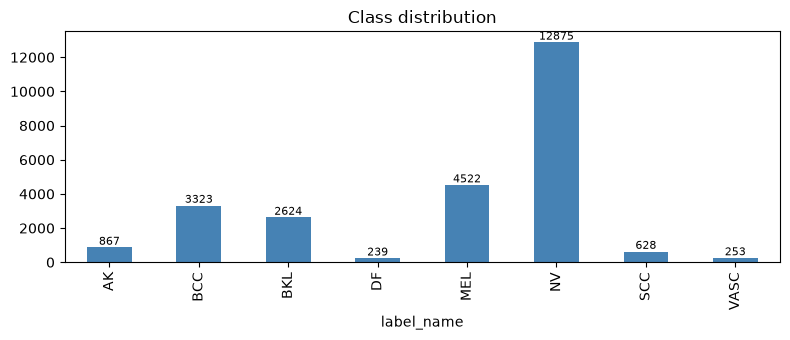

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def discover_dataset(root: Path) -> pd.DataFrame:
    """Return DataFrame[path, label_name]. Supports
    (a) class sub-folders at any depth (train/val/test split folders are merged) and
    (b) ISIC_2019_Training_GroundTruth.csv (one-hot) + an image folder."""
    files = [p for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS]
    if not files:
        raise RuntimeError(f"No images found under {root}")

    csvs = [c for c in root.rglob("*.csv") if "groundtruth" in c.name.lower()]
    parents = pd.Series([p.parent.name for p in files])
    if csvs and parents.nunique() < 3:          # (b) CSV layout
        gt = pd.read_csv(csvs[0])
        cls_cols = [c for c in gt.columns if c != "image" and c != "UNK" and gt[c].sum() > 0]
        gt["label_name"] = gt[cls_cols].idxmax(axis=1)
        by_stem = {p.stem: str(p.resolve()) for p in files}
        gt["path"] = gt["image"].map(by_stem)
        df = gt.dropna(subset=["path"])[["path", "label_name"]]
    else:                                        # (a) folder-per-class layout
        df = pd.DataFrame({"path": [str(p.resolve()) for p in files],
                           "label_name": parents.values})
    # Drop duplicate files (same file name appearing in several split folders)
    df["stem"] = df["path"].map(lambda s: Path(s).stem)
    df = df.drop_duplicates(subset=["stem", "label_name"]).drop(columns="stem")
    return df.reset_index(drop=True)

df_all = discover_dataset(DATA_ROOT)
CLASS_NAMES = sorted(df_all["label_name"].unique())
NUM_CLASSES = len(CLASS_NAMES)
df_all["label"] = df_all["label_name"].map({c: i for i, c in enumerate(CLASS_NAMES)})
print(f"{len(df_all)} images | {NUM_CLASSES} classes: {CLASS_NAMES}")

if SUBSET_FRACTION < 1.0:
    df_all, _ = train_test_split(df_all, train_size=SUBSET_FRACTION,
                                 stratify=df_all["label"], random_state=SEED)
    df_all = df_all.reset_index(drop=True)
    print(f"Using stratified subset: {len(df_all)} images")

counts = df_all["label_name"].value_counts().reindex(CLASS_NAMES)
ax = counts.plot.bar(figsize=(8, 3.5), color="steelblue", title="Class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150); plt.show()

## 5. One-time resize cache (256px)
Many ISIC images are 1024px+; decoding them every epoch is slow. Done once, skipped on later runs.

In [5]:
def cache_one(args):
    """Resize one image (shorter side -> CACHE_SIZE) and save it as JPEG in CACHE_DIR."""
    src, dst = args
    if dst.exists():
        return
    try:
        with Image.open(src) as im:
            im = im.convert("RGB")
            w, h = im.size
            s = CACHE_SIZE / min(w, h)
            if s < 1:
                im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
            dst.parent.mkdir(parents=True, exist_ok=True)
            im.save(dst, "JPEG", quality=95)
    except Exception as e:
        print("Failed:", src, e)

jobs = [(Path(p), CACHE_DIR / ln / (Path(p).stem + ".jpg"))
        for p, ln in zip(df_all["path"], df_all["label_name"])]
with ThreadPoolExecutor(max_workers=max(4, (os.cpu_count() or 2) * 2)) as ex:
    list(tqdm(ex.map(cache_one, jobs), total=len(jobs), desc="Caching"))
df_all["path"] = [str(d.resolve()) for _, d in jobs]
df_all = df_all[df_all["path"].map(os.path.exists)].reset_index(drop=True)
print("Cached images:", len(df_all), "->", CACHE_DIR.resolve())

Caching:   0%|          | 0/25331 [00:00<?, ?it/s]

Cached images: 25331 -> F:\Rakib\isic_cache_256


## 6. Split (train / server-val / test) and client partition (non-IID)
- server-val: evaluates the global model every round and selects the best round.
- test: used only once at the end, for the reported results (no selection bias).

train 17731 | server-val 2533 | test 5067


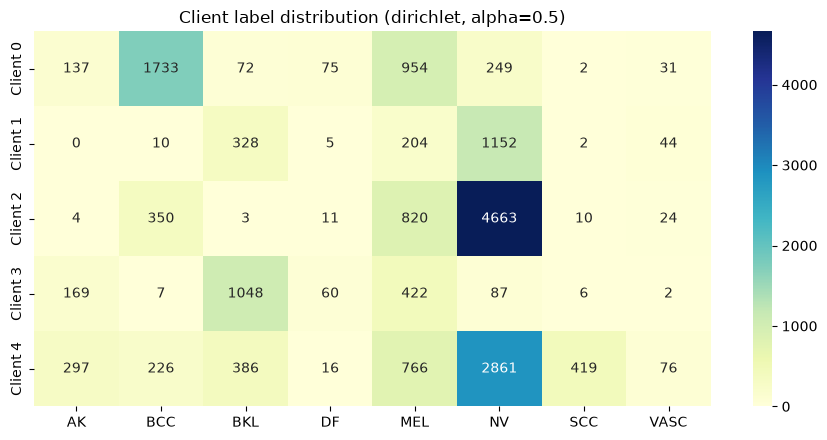

In [6]:
df_trainpool, df_test = train_test_split(df_all, test_size=TEST_FRAC,
                                         stratify=df_all["label"], random_state=SEED)
df_train, df_val = train_test_split(df_trainpool, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                    stratify=df_trainpool["label"], random_state=SEED)
df_train, df_val, df_test = (d.reset_index(drop=True) for d in (df_train, df_val, df_test))
print(f"train {len(df_train)} | server-val {len(df_val)} | test {len(df_test)}")

def partition_indices(labels: np.ndarray, n_clients: int, method: str, alpha: float,
                      seed: int = SEED, min_size: int = 20):
    """Split sample indices among clients: IID, or Dirichlet label-skew (non-IID)."""
    rng = np.random.default_rng(seed)
    if method == "iid":
        idx = rng.permutation(len(labels))
        return [p.tolist() for p in np.array_split(idx, n_clients)]
    for _ in range(1000):                       # retry until every client has >= min_size samples
        parts = [[] for _ in range(n_clients)]
        for c in np.unique(labels):
            idx_c = rng.permutation(np.where(labels == c)[0])
            props = rng.dirichlet(alpha * np.ones(n_clients))
            cuts = (np.cumsum(props) * len(idx_c)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(idx_c, cuts)):
                parts[k].extend(chunk.tolist())
        if min(len(p) for p in parts) >= min_size:
            return parts
    raise RuntimeError("Could not create partitions; increase alpha or reduce NUM_CLIENTS")

parts = partition_indices(df_train["label"].values, NUM_CLIENTS, PARTITION, DIRICHLET_ALPHA)
CLIENT_DATA = []   # per client: (train_records, localval_records); records = list[(path, label)]
for k, idx in enumerate(parts):
    d = df_train.iloc[idx]
    vc = d["label"].value_counts()
    strat = d["label"] if vc.min() >= 2 and int(len(d) * LOCAL_VAL_FRAC) >= len(vc) else None
    tr, va = train_test_split(d, test_size=LOCAL_VAL_FRAC, stratify=strat, random_state=SEED)
    CLIENT_DATA.append((list(zip(tr["path"], tr["label"])), list(zip(va["path"], va["label"]))))

# Heatmap of samples per class per client
mat = np.zeros((NUM_CLIENTS, NUM_CLASSES), dtype=int)
for k, idx in enumerate(parts):
    for c, n in df_train.iloc[idx]["label"].value_counts().items():
        mat[k, c] = n
plt.figure(figsize=(9, 0.6 * NUM_CLIENTS + 1.5))
sns.heatmap(mat, annot=True, fmt="d", cmap="YlGnBu", xticklabels=CLASS_NAMES,
            yticklabels=[f"Client {k}" for k in range(NUM_CLIENTS)])
plt.title(f"Client label distribution ({PARTITION}, alpha={DIRICHLET_ALPHA})")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "client_partition.png", dpi=150); plt.show()

## 7. PyTorch Dataset and transforms

In [7]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics
TRAIN_TF = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.02),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
EVAL_TF = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 256 / 224)), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ISICDataset(Dataset):
    """Dataset over a list of (image_path, label) records."""
    def __init__(self, records, tf):
        self.records, self.tf = records, tf
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        path, label = self.records[i]
        with Image.open(path) as im:
            x = self.tf(im.convert("RGB"))
        return x, int(label)

def make_loader(records, train: bool):
    return DataLoader(ISICDataset(records, TRAIN_TF if train else EVAL_TF),
                      batch_size=BATCH_SIZE, shuffle=train,
                      drop_last=train and len(records) > BATCH_SIZE,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
                      persistent_workers=False)

VAL_RECORDS  = list(zip(df_val["path"], df_val["label"]))
TEST_RECORDS = list(zip(df_test["path"], df_test["label"]))

## 8. Models — ResNet50, DenseNet201, EfficientNetV2-S (torchvision, ImageNet-pretrained)
DenseNet201 is the largest DenseNet in torchvision; EfficientNetV2 is the latest EfficientNet generation.

In [8]:
def build_model(name: str, num_classes: int, pretrained: bool = False) -> nn.Module:
    """Build a backbone and replace its classification head with num_classes outputs."""
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "densenet201":
        m = models.densenet201(weights=models.DenseNet201_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
    elif name == "efficientnet_v2_s":
        m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(name)
    return m

# Download pretrained weights once in the main process (clients then receive them from the server)
for name in MODELS:
    m = build_model(name, NUM_CLASSES, PRETRAINED)
    print(f"{name:18s} params: {sum(p.numel() for p in m.parameters())/1e6:.1f}M")
del m

resnet50           params: 23.5M
Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to C:\Users\USER/.cache\torch\hub\checkpoints\densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:01<00:00, 41.9MB/s]


densenet201        params: 18.1M
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to C:\Users\USER/.cache\torch\hub\checkpoints\efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:01<00:00, 45.3MB/s]


efficientnet_v2_s  params: 20.2M


## 9. Training / evaluation helpers and metrics

In [9]:
def class_weights_from(records, num_classes):
    """Square-root inverse-frequency class weights from a client's local labels."""
    counts = np.bincount([l for _, l in records], minlength=num_classes).astype(float)
    w = np.where(counts > 0, np.sqrt(counts.sum() / (num_classes * np.maximum(counts, 1))), 0.0)
    w = w / w[counts > 0].mean()
    return torch.tensor(w, dtype=torch.float32)

def train_local(model, loader, epochs, lr, device, class_weights=None):
    """Local client training; returns the mean training loss."""
    model.to(device).train()
    crit = nn.CrossEntropyLoss(weight=class_weights.to(device) if class_weights is not None else None,
                               label_smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    amp = USE_AMP and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    total, n = 0.0, 0
    for _ in range(epochs):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            total += loss.item() * y.size(0); n += y.size(0)
    return total / max(n, 1)

@torch.no_grad()
def predict(model, loader, device):
    """Return (mean loss, true labels, softmax probabilities)."""
    model.to(device).eval()
    amp = USE_AMP and device.type == "cuda"
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            out = model(x)
        loss += crit(out.float(), y).item()
        ys.append(y.cpu()); ps.append(torch.softmax(out.float(), 1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return loss / len(y), y, p

def compute_metrics(y, prob, num_classes):
    pred = prob.argmax(1)
    m = {"acc": accuracy_score(y, pred),
         "bal_acc": balanced_accuracy_score(y, pred),      # official ISIC 2019 metric
         "f1_macro": f1_score(y, pred, average="macro", zero_division=0)}
    try:
        m["auc_macro"] = roc_auc_score(y, prob, multi_class="ovr", average="macro",
                                       labels=list(range(num_classes)))
    except ValueError:
        m["auc_macro"] = float("nan")
    return m

def cosine_lr(server_round, num_rounds):
    """Learning rate for a given round: cosine decay from LR to LR_MIN."""
    t = (server_round - 1) / max(1, num_rounds - 1)
    return LR_MIN + 0.5 * (LR - LR_MIN) * (1 + math.cos(math.pi * t))

## 10. Flower ClientApp (Message API)
Each virtual client (partition-id) trains on its own data and returns updated weights.
The server sends the model name in config["model-name"], so one ClientApp serves all three models.

In [10]:
client_app = ClientApp()

@client_app.train()
def client_train(msg: Message, context: Context):
    pid = int(context.node_config["partition-id"])
    cfg = msg.content["config"]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Load the current global model
    model = build_model(str(cfg["model-name"]), NUM_CLASSES, pretrained=False)
    model.load_state_dict(msg.content["arrays"].to_torch_state_dict())

    # Local training
    train_records, _ = CLIENT_DATA[pid]
    lr = cosine_lr(int(cfg["server-round"]), int(cfg["num-rounds"]))
    cw = class_weights_from(train_records, NUM_CLASSES) if USE_CLASS_WEIGHTS else None
    loss = train_local(model, make_loader(train_records, train=True),
                       int(cfg["local-epochs"]), lr, device, cw)

    # Reply with updated weights; "num-examples" is used by FedAvg for weighting
    content = RecordDict({
        "arrays": ArrayRecord(model.state_dict()),
        "metrics": MetricRecord({"train_loss": loss, "num-examples": len(train_records)}),
    })
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return Message(content=content, reply_to=msg)

@client_app.evaluate()
def client_evaluate(msg: Message, context: Context):
    pid = int(context.node_config["partition-id"])
    cfg = msg.content["config"]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Evaluate the global model on this client's local validation split
    model = build_model(str(cfg["model-name"]), NUM_CLASSES, pretrained=False)
    model.load_state_dict(msg.content["arrays"].to_torch_state_dict())
    _, val_records = CLIENT_DATA[pid]
    loss, y, p = predict(model, make_loader(val_records, train=False), device)

    content = RecordDict({"metrics": MetricRecord({
        "local_val_loss": loss, "local_val_acc": float((p.argmax(1) == y).mean()),
        "num-examples": len(val_records)})})
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return Message(content=content, reply_to=msg)

## 11. Flower ServerApp — FedAvg + per-round server-val evaluation + best-model checkpoint

In [11]:
HISTORY = {}   # model_name -> list of per-round metric dicts (filled by the ServerApp thread)

def make_server_app(model_name: str) -> ServerApp:
    server_app = ServerApp()

    @server_app.main()
    def main(grid: Grid, context: Context) -> None:
        init_model = build_model(model_name, NUM_CLASSES, pretrained=PRETRAINED)
        eval_model = build_model(model_name, NUM_CLASSES, pretrained=False)
        val_loader = make_loader(VAL_RECORDS, train=False)
        HISTORY[model_name] = []
        best = {"bal_acc": -1.0, "round": 0}
        t0 = time.time()

        def central_evaluate(server_round: int, arrays: ArrayRecord) -> MetricRecord:
            """Evaluate the aggregated global model on server-val; save it if it is the best so far."""
            eval_model.load_state_dict(arrays.to_torch_state_dict())
            loss, y, p = predict(eval_model, val_loader, DEVICE)
            m = compute_metrics(y, p, NUM_CLASSES)
            m.update(round=server_round, val_loss=loss, elapsed_min=(time.time() - t0) / 60)
            HISTORY[model_name].append(m)
            if server_round > 0 and m["bal_acc"] > best["bal_acc"]:
                best.update(bal_acc=m["bal_acc"], round=server_round)
                torch.save(eval_model.state_dict(), OUTPUT_DIR / f"{model_name}_best.pt")
            print(f"[{model_name}] round {server_round:2d} | val_loss {loss:.4f} | acc {m['acc']:.4f} "
                  f"| bal_acc {m['bal_acc']:.4f} | f1 {m['f1_macro']:.4f} | auc {m['auc_macro']:.4f} "
                  f"| {m['elapsed_min']:.1f} min")
            eval_model.cpu()   # free GPU memory for the clients
            return MetricRecord({k: float(v) for k, v in m.items()})

        strategy = FedAvg(fraction_train=FRACTION_TRAIN, fraction_evaluate=FRACTION_EVAL,
                          min_train_nodes=max(1, int(FRACTION_TRAIN * NUM_CLIENTS)),
                          min_evaluate_nodes=max(1, int(FRACTION_EVAL * NUM_CLIENTS)) if FRACTION_EVAL > 0 else 1,
                          min_available_nodes=NUM_CLIENTS)
        result = strategy.start(
            grid=grid,
            initial_arrays=ArrayRecord(init_model.state_dict()),
            num_rounds=NUM_ROUNDS,
            train_config=ConfigRecord({"model-name": model_name, "local-epochs": LOCAL_EPOCHS,
                                       "num-rounds": NUM_ROUNDS}),
            evaluate_config=ConfigRecord({"model-name": model_name}),
            evaluate_fn=central_evaluate,
        )
        torch.save(result.arrays.to_torch_state_dict(), OUTPUT_DIR / f"{model_name}_final.pt")
        print(f"[{model_name}] best server-val bal_acc {best['bal_acc']:.4f} at round {best['round']}")

    return server_app

## 12. Run the simulation — the three models one after another
DenseNet201 is the slowest of the three. You can run one model at a time via MODELS;
each model's history is saved to JSON, so results from separate runs are combined in sections 13-14.

In [12]:
backend_config = {
    "client_resources": {"num_cpus": CLIENT_NUM_CPUS, "num_gpus": CLIENT_NUM_GPUS},
    "init_args": {"include_dashboard": False, "log_to_driver": True},
}

for model_name in MODELS:
    print(f"\n{'=' * 25} Federated training: {model_name} {'=' * 25}")
    seed_everything()
    run_simulation(server_app=make_server_app(model_name), client_app=client_app,
                   num_supernodes=NUM_CLIENTS, backend_config=backend_config)
    with open(OUTPUT_DIR / f"{model_name}_history.json", "w") as f:
        json.dump(HISTORY[model_name], f, indent=2)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        



========================= Federated training: resnet50 =========================


INFO :      Starting FedAvg strategy:
INFO :      	├── Number of rounds: 10
INFO :      	├── ArrayRecord (89.98 MB)
INFO :      	├── ConfigRecord (train): {'model-name': resnet50, 'local-epochs': 1, 'num-rounds': 10}
INFO :      	├── ConfigRecord (evaluate): {'model-name': resnet50}
INFO :      	├──> Sampling:
INFO :      	│	├──Fraction: train (1.00) | evaluate ( 1.00)
INFO :      	│	├──Minimum nodes: train (5) | evaluate (5)
INFO :      	│	└──Minimum available nodes: 5
INFO :      	└──> Keys in records:
INFO :      		├── Weighted by: 'num-examples'
INFO :      		├── ArrayRecord key: 'arrays'
INFO :      		└── ConfigRecord key: 'config'
INFO :      
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_mem

[resnet50] round  0 | val_loss 2.0481 | acc 0.1674 | bal_acc 0.1374 | f1 0.0969 | auc 0.5031 | 1.0 min


(ClientAppActor pid=32448) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
(ClientAppActor pid=32448)   return data.pin_memory(device)
(ClientAppActor pid=32448) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
(ClientAppActor pid=32448)   return data.pin_memory(device)
(raylet) Stack (most recent call first): [repeated 2x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en

...

[efficientnet_v2_s] round  8 | val_loss 0.8768 | acc 0.7722 | bal_acc 0.6510 | f1 0.6436 | auc 0.9421 | 31.0 min


INFO :      aggregate_train: Received 5 results and 0 failures
INFO :      	└──> Aggregated MetricRecord: {'train_loss': 1.7763922757333075}
INFO :      configure_evaluate: Sampled 5 nodes (out of 5)
INFO :      aggregate_evaluate: Received 5 results and 0 failures
INFO :      	└──> Aggregated MetricRecord: {'local_val_loss': 0.8649627107220728, 'local_val_acc': 0.7804054054054054}
INFO :      Global evaluation
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally

[efficientnet_v2_s] round  9 | val_loss 0.8769 | acc 0.7687 | bal_acc 0.6402 | f1 0.6347 | auc 0.9426 | 34.7 min


INFO :      aggregate_train: Received 5 results and 0 failures
INFO :      	└──> Aggregated MetricRecord: {'train_loss': 1.83773593217404}
INFO :      configure_evaluate: Sampled 5 nodes (out of 5)
INFO :      aggregate_evaluate: Received 5 results and 0 failures
INFO :      	└──> Aggregated MetricRecord: {'local_val_loss': 0.8718255323332709, 'local_val_acc': 0.7792792792792793}
INFO :      Global evaluation
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally a

[efficientnet_v2_s] round 10 | val_loss 0.8837 | acc 0.7687 | bal_acc 0.6396 | f1 0.6342 | auc 0.9417 | 38.4 min
[efficientnet_v2_s] best server-val bal_acc 0.6671 at round 7


## 13. Round-wise learning curves (server-val)

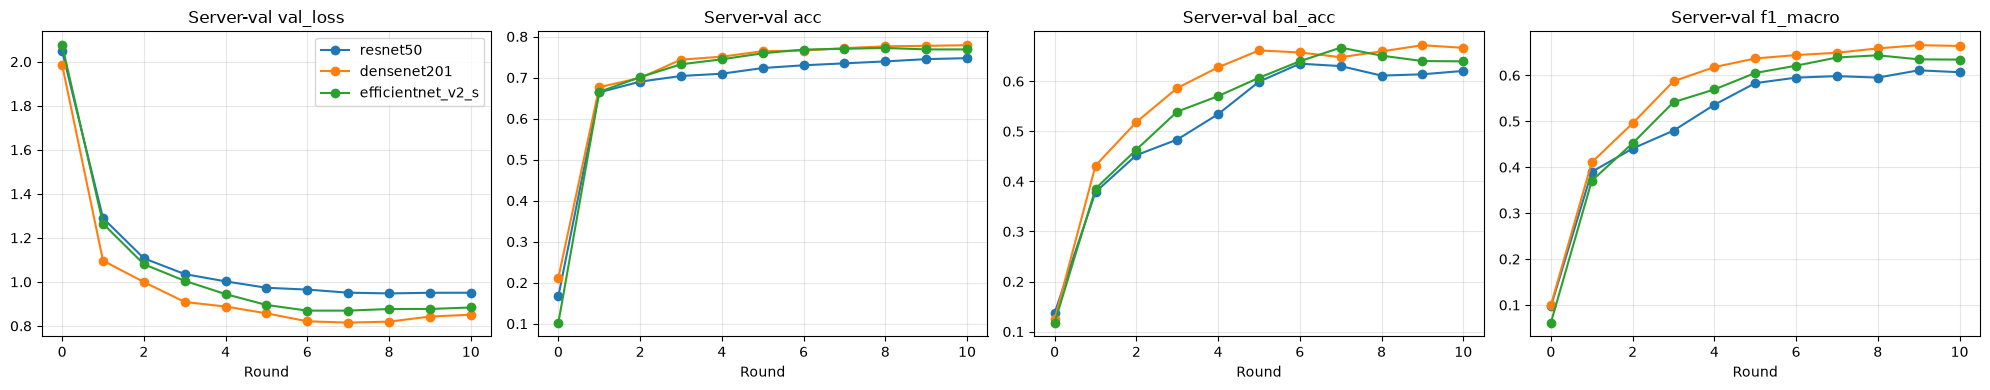

In [13]:
for name in MODELS:                       # reload in case models were run in separate sessions
    fp = OUTPUT_DIR / f"{name}_history.json"
    if name not in HISTORY and fp.exists():
        HISTORY[name] = json.load(open(fp))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for name, hist in HISTORY.items():
    h = pd.DataFrame(hist)
    for ax, key in zip(axes, ["val_loss", "acc", "bal_acc", "f1_macro"]):
        ax.plot(h["round"], h[key], marker="o", label=name)
        ax.set_title(f"Server-val {key}"); ax.set_xlabel("Round"); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "fl_learning_curves.png", dpi=150); plt.show()

## 14. Final held-out test evaluation (weights from the best round)

In [14]:
test_loader = make_loader(TEST_RECORDS, train=False)
summary, test_probs = [], {}
for name in HISTORY:
    model = build_model(name, NUM_CLASSES)
    model.load_state_dict(torch.load(OUTPUT_DIR / f"{name}_best.pt", map_location="cpu"))
    loss, y_test, p = predict(model, test_loader, DEVICE)
    test_probs[name] = p
    m = compute_metrics(y_test, p, NUM_CLASSES)
    best_round = max(HISTORY[name][1:], key=lambda r: r["bal_acc"])["round"]
    summary.append({"model": name, "best_round": best_round, "test_loss": loss, **m})
    print(f"\n==== {name} (best round {best_round}) ====")
    print(classification_report(y_test, p.argmax(1), target_names=CLASS_NAMES, digits=4, zero_division=0))
    del model

summary_df = pd.DataFrame(summary).set_index("model").round(4)
summary_df.to_csv(OUTPUT_DIR / "test_summary.csv")
summary_df

c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



==== resnet50 (best round 6) ====
              precision    recall  f1-score   support

          AK     0.4367    0.3988    0.4169       173
         BCC     0.7313    0.6917    0.7110       665
         BKL     0.5660    0.4000    0.4688       525
          DF     0.3544    0.5833    0.4409        48
         MEL     0.6086    0.6759    0.6405       904
          NV     0.8444    0.8680    0.8560      2575
         SCC     0.3729    0.3492    0.3607       126
        VASC     0.6885    0.8235    0.7500        51

    accuracy                         0.7300      5067
   macro avg     0.5754    0.5988    0.5806      5067
weighted avg     0.7268    0.7300    0.7261      5067



c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



==== densenet201 (best round 9) ====
              precision    recall  f1-score   support

          AK     0.4819    0.5376    0.5082       173
         BCC     0.7873    0.7624    0.7746       665
         BKL     0.6801    0.3848    0.4915       525
          DF     0.6444    0.6042    0.6237        48
         MEL     0.6778    0.6305    0.6533       904
          NV     0.8323    0.9274    0.8773      2575
         SCC     0.4649    0.4206    0.4417       126
        VASC     0.7031    0.8824    0.7826        51

    accuracy                         0.7671      5067
   macro avg     0.6590    0.6437    0.6441      5067
weighted avg     0.7589    0.7671    0.7571      5067



c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



==== efficientnet_v2_s (best round 7) ====
              precision    recall  f1-score   support

          AK     0.4598    0.4624    0.4611       173
         BCC     0.7273    0.8180    0.7700       665
         BKL     0.6712    0.3733    0.4798       525
          DF     0.4507    0.6667    0.5378        48
         MEL     0.6860    0.6405    0.6625       904
          NV     0.8471    0.9017    0.8736      2575
         SCC     0.3788    0.3968    0.3876       126
        VASC     0.6615    0.8431    0.7414        51

    accuracy                         0.7590      5067
   macro avg     0.6103    0.6378    0.6142      5067
weighted avg     0.7539    0.7590    0.7508      5067



,best_round,test_loss,acc,bal_acc,f1_macro,auc_macro
model,,,,,,
resnet50,6,0.9702,0.7300,0.5988,0.5806,0.9270
densenet201,9,0.8626,0.7671,0.6437,0.6441,0.9443
efficientnet_v2_s,7,0.8883,0.7590,0.6378,0.6142,0.9338


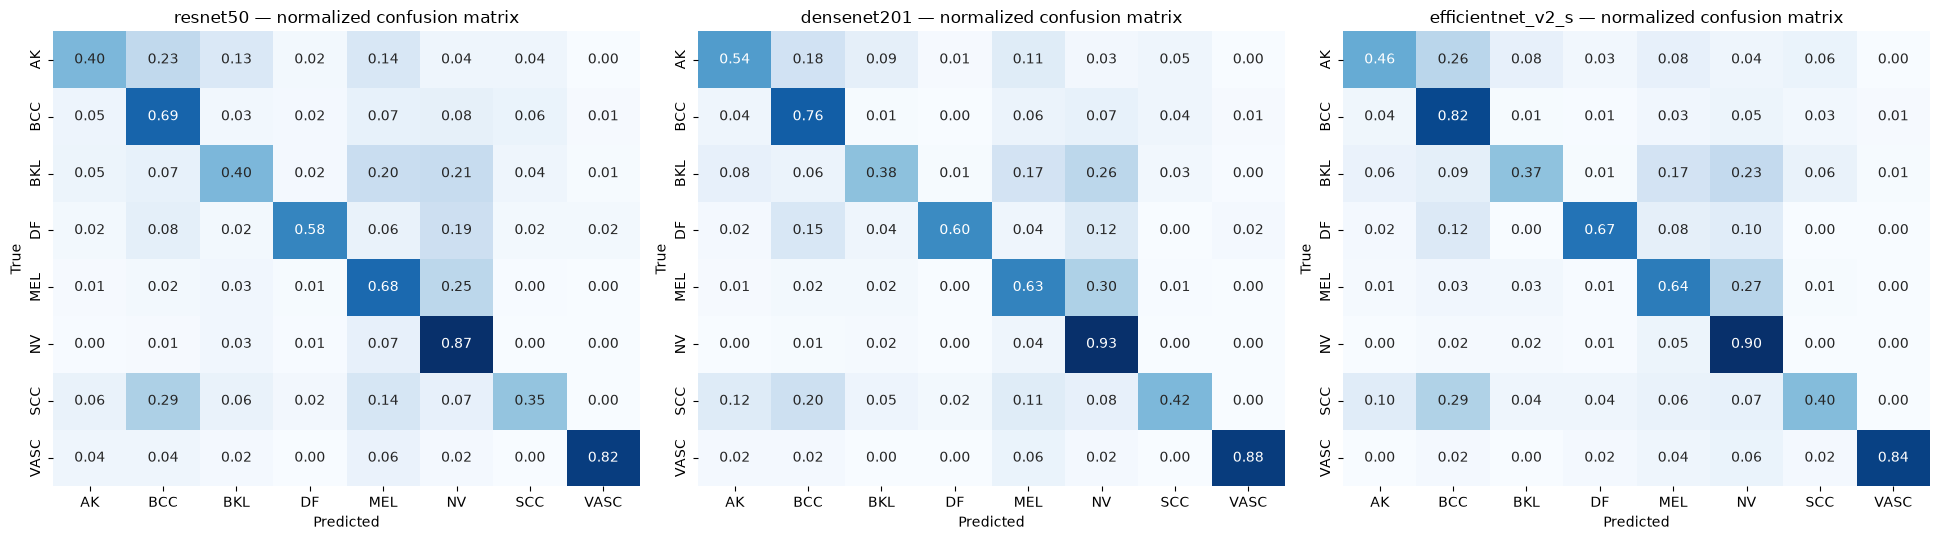

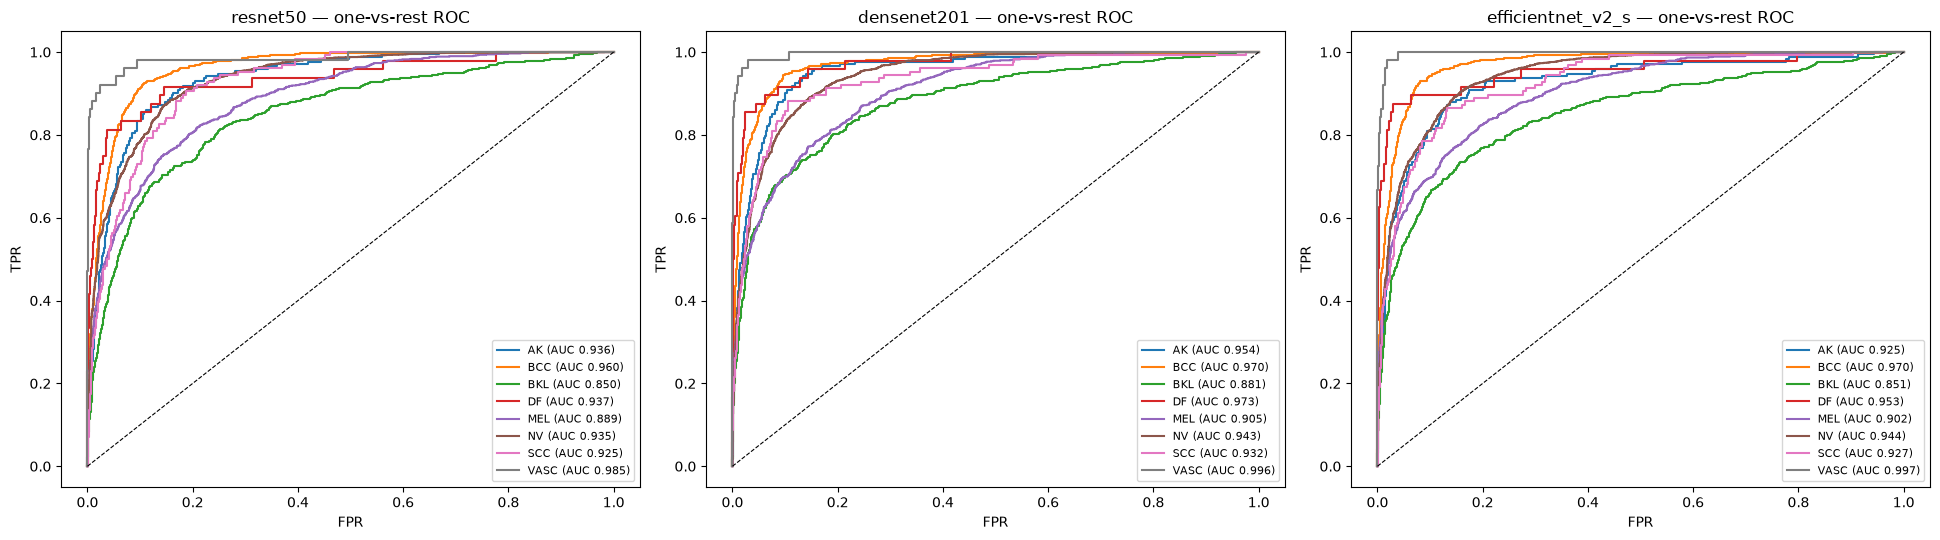

All outputs saved in: F:\Rakib\fl_isic_outputs


In [15]:
# Normalized confusion matrices
fig, axes = plt.subplots(1, len(test_probs), figsize=(6.5 * len(test_probs), 5.5))
axes = np.atleast_1d(axes)
for ax, (name, p) in zip(axes, test_probs.items()):
    cm = confusion_matrix(y_test, p.argmax(1), labels=range(NUM_CLASSES), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{name} — normalized confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150); plt.show()

# One-vs-rest ROC curves
fig, axes = plt.subplots(1, len(test_probs), figsize=(6.5 * len(test_probs), 5.5))
axes = np.atleast_1d(axes)
for ax, (name, p) in zip(axes, test_probs.items()):
    for c in range(NUM_CLASSES):
        if (y_test == c).any():
            fpr, tpr, _ = roc_curve(y_test == c, p[:, c])
            ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name} — one-vs-rest ROC"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=150); plt.show()

print("All outputs saved in:", OUTPUT_DIR.resolve())